# Kenya Mobile Money: 10 Questions, Answered Twice

A year of synthetic Kenyan mobile-money activity: 6,000 transactions from 800 customers across M-Pesa, Airtel Money, T-Kash and Equitel in 2024.

Each of the 10 questions is answered **in pandas** in this notebook and **in SQL** in `sql/questions.sql`. The notebook loads the CSV into an in-memory SQLite database, runs each SQL query and checks it agrees with the pandas result. That way every answer is cross-validated by two independent implementations.

Unless a question says otherwise, only `status = 'Completed'` transactions count.

In [1]:
import re
import sqlite3
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

raw = pd.read_csv("../data/kenya_mobile_money_transactions.csv", parse_dates=["transaction_timestamp"])
done = raw[raw["status"] == "Completed"].copy()
print(f"{len(raw):,} transactions | {len(done):,} completed | {raw['customer_id'].nunique()} customers | {raw['county'].nunique()} counties")

# Load the same CSV into SQLite and index the SQL file by query name
db = sqlite3.connect(":memory:")
sql_df = pd.read_csv("../data/kenya_mobile_money_transactions.csv")
sql_df.to_sql("txns", db, index=False)
queries = dict(re.findall(r"-- name: (q\d+)\n(.*?;)", open("../sql/questions.sql").read(), flags=re.S))

def sql(name):
    return pd.read_sql(queries[name], db)

6,000 transactions | 5,665 completed | 800 customers | 20 counties


## Q1. Monthly fee revenue and month-over-month growth

Fastest growth: 2024-05 (+11.2%)   [pandas and SQL agree]


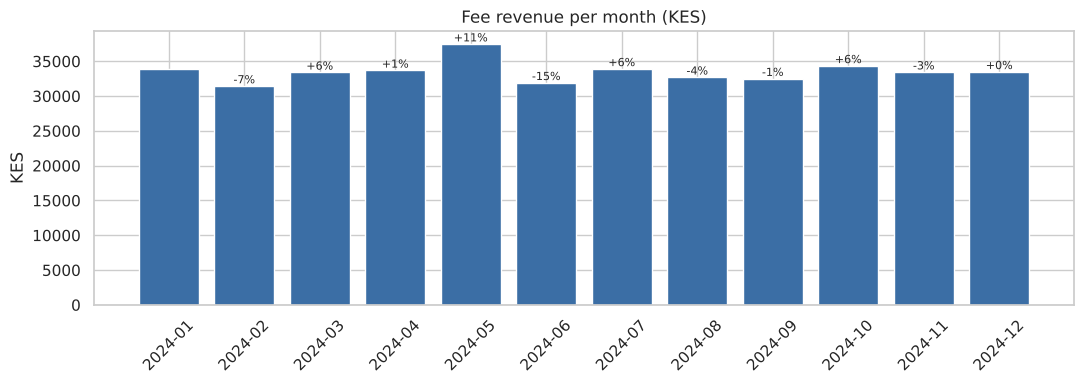

,fee_revenue,mom_pct
transaction_timestamp,,
2024-01,33876.0,NaN
2024-02,31452.0,-7.16
2024-03,33417.0,6.25
2024-04,33705.0,0.86
2024-05,37474.0,11.18
2024-06,31925.0,-14.81
2024-07,33923.0,6.26
2024-08,32716.0,-3.56
2024-09,32513.0,-0.62


In [2]:
q1 = (done.set_index("transaction_timestamp")["transaction_fee_kes"]
          .resample("MS").sum().to_frame("fee_revenue"))
q1["mom_pct"] = (q1["fee_revenue"].pct_change() * 100).round(2)
q1.index = q1.index.strftime("%Y-%m")

assert np.allclose(q1["fee_revenue"].values, sql("q1")["fee_revenue"].values, atol=0.01)
fastest = q1["mom_pct"].idxmax()
print(f"Fastest growth: {fastest} ({q1.loc[fastest, 'mom_pct']:+.1f}%)   [pandas and SQL agree]")

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(q1.index, q1["fee_revenue"], color="#3b6ea5")
ax.set(title="Fee revenue per month (KES)", ylabel="KES")
for i, v in enumerate(q1["mom_pct"]):
    if not np.isnan(v):
        ax.text(i, q1["fee_revenue"].iloc[i], f"{v:+.0f}%", ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
q1

## Q2. When is the platform busiest?

Busiest block: Wed 09:00-10:00 with 69 transactions   [pandas and SQL agree]


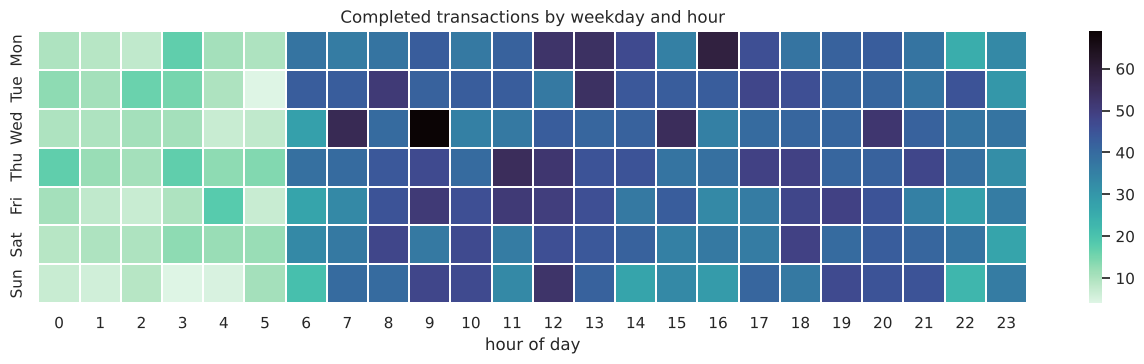

In [3]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
grid = (done.assign(day=done["transaction_timestamp"].dt.dayofweek, hour=done["transaction_timestamp"].dt.hour)
            .pivot_table(index="day", columns="hour", values="transaction_id", aggfunc="count", fill_value=0))
grid.index = [days[i] for i in grid.index]

peak_day, peak_hour = grid.stack().idxmax()
top_sql = sql("q2").iloc[0]
assert grid.stack().max() == top_sql["txn_count"]
print(f"Busiest block: {peak_day} {peak_hour:02d}:00-{peak_hour + 1:02d}:00 with {grid.stack().max()} transactions   [pandas and SQL agree]")

plt.figure(figsize=(13, 3.8))
sns.heatmap(grid, cmap="mako_r", linewidths=0.3)
plt.title("Completed transactions by weekday and hour")
plt.xlabel("hour of day")
plt.tight_layout()
plt.show()

## Q3. Top 3 customers by value in each county

In [4]:
totals = done.groupby(["county", "customer_id", "customer_name"], as_index=False)["amount_kes"].sum()
totals["rank"] = totals.groupby("county")["amount_kes"].rank(method="min", ascending=False).astype(int)
q3 = totals[totals["rank"] <= 3].sort_values(["county", "rank"]).reset_index(drop=True)

assert len(q3) == len(sql("q3"))
print(f"{len(q3)} rows across {q3['county'].nunique()} counties   [pandas and SQL agree]")
q3.head(9)

60 rows across 20 counties   [pandas and SQL agree]


,county,customer_id,customer_name,amount_kes,rank
0,Bomet,CUST00465,Mutua Musyoka,330868.23,1
1,Bomet,CUST00709,Kagwe Kamau,310710.67,2
2,Bomet,CUST00185,Wairimu Otieno,309514.15,3
3,Bungoma,CUST00229,Rotich Gichuru,472761.38,1
4,Bungoma,CUST00331,Nafula Langat,391095.20,2
5,Bungoma,CUST00570,Maina Chepkwony,374698.69,3
6,Garissa,CUST00573,Kagwe Chepkwony,366407.86,1
7,Garissa,CUST00388,Njoroge Kiplagat,282178.41,2
8,Garissa,CUST00398,Kariuki Gichuru,270122.27,3


## Q4. Volume spikes against the 7-day rolling average

4 days exceeded 1.5x their rolling average   [pandas and SQL agree]


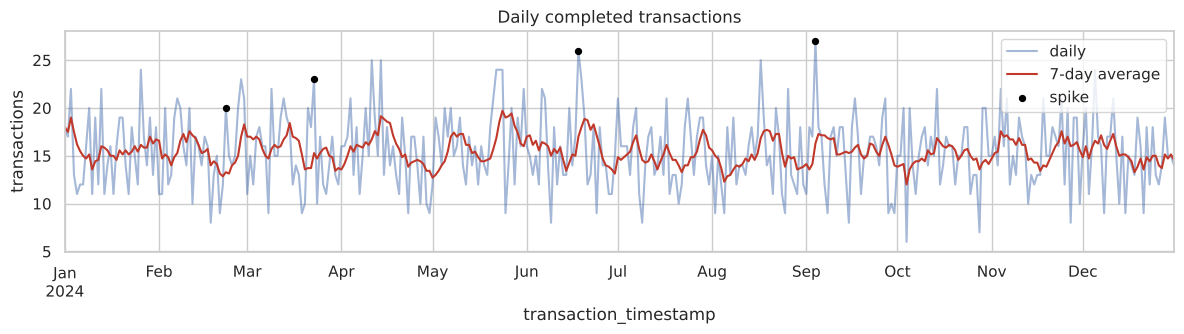

In [5]:
daily = done.set_index("transaction_timestamp").resample("D")["transaction_id"].count().to_frame("txns")
daily = daily[daily["txns"] > 0]  # SQL only sees days that had activity, so match that
daily["rolling_7d"] = daily["txns"].rolling(7, min_periods=1).mean()
spikes = daily[daily["txns"] > 1.5 * daily["rolling_7d"]]

assert len(spikes) == sql("q4")["spike_days"].iloc[0]
print(f"{len(spikes)} days exceeded 1.5x their rolling average   [pandas and SQL agree]")

ax = daily["txns"].plot(figsize=(12, 3.5), alpha=0.5, label="daily")
daily["rolling_7d"].plot(ax=ax, color="#c0392b", label="7-day average")
ax.scatter(spikes.index, spikes["txns"], color="black", zorder=3, s=18, label="spike")
ax.set(title="Daily completed transactions", ylabel="transactions")
ax.legend()
plt.tight_layout()
plt.show()

## Q5. RFM segmentation

Recency, frequency and monetary value per customer, each scored 1 to 5 by quintile. "Champions" scored 4 or 5 on all three.

In [6]:
ref = done["transaction_timestamp"].max()
rfm = done.groupby("customer_id").agg(
    recency_days=("transaction_timestamp", lambda s: (ref - s.max()).total_seconds() / 86400),
    frequency=("transaction_id", "count"),
    monetary=("amount_kes", "sum"),
)

def quintile(series, reverse=False):
    # rank first so ties split evenly, like SQL's NTILE
    q = pd.qcut(series.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
    return 6 - q if reverse else q

rfm["R"] = quintile(rfm["recency_days"], reverse=True)
rfm["F"] = quintile(rfm["frequency"])
rfm["M"] = quintile(rfm["monetary"])

def segment(r):
    if r.R >= 4 and r.F >= 4 and r.M >= 4:
        return "Champions"
    if r.R <= 2 and r.F >= 3:
        return "At risk"
    if r.R >= 4:
        return "Recent"
    return "Others"

rfm["segment"] = rfm.apply(segment, axis=1)
seg = rfm.groupby("segment").agg(customers=("R", "size"), avg_value_kes=("monetary", "mean")).round(0)
seg = seg.sort_values("customers", ascending=False)
print("SQL segment sizes:", dict(sql("q5").values))
seg

SQL segment sizes: {'Others': 349, 'Recent': 198, 'At risk': 130, 'Champions': 122}


,customers,avg_value_kes
segment,,
Others,349,177698.0
Recent,199,169877.0
At risk,130,234796.0
Champions,121,332631.0


Pandas and SQL can split tied customers slightly differently at quintile boundaries, so segment counts may differ by a customer or two. The segments themselves are consistent.

## Q6. Which channel and transaction type fail most?

This one uses all statuses. "Problem rate" means the share of transactions that ended `Failed` or `Reversed`. Only combinations with at least 20 transactions are ranked, so small groups don't top the list by chance.

In [7]:
q6 = (raw.assign(problem=raw["status"].isin(["Failed", "Reversed"]))
         .groupby(["channel", "transaction_type"])
         .agg(txns=("problem", "size"), problem_rate_pct=("problem", "mean")))
q6["problem_rate_pct"] = (q6["problem_rate_pct"] * 100).round(2)
q6 = q6[q6["txns"] >= 20].sort_values("problem_rate_pct", ascending=False)

assert np.isclose(q6["problem_rate_pct"].iloc[0], sql("q6")["problem_rate_pct"].iloc[0])
print("Least reliable:", " / ".join(q6.index[0]), f"({q6['problem_rate_pct'].iloc[0]}%)   [pandas and SQL agree]")
q6.head(8)

Least reliable: T-Kash / Buy Goods (Till) (15.15%)   [pandas and SQL agree]


txns  problem_rate_pct
channel      transaction_type                        
T-Kash       Buy Goods (Till)    33             15.15
             Pay Bill            35             11.43
Equitel      Withdraw Cash       20             10.00
             Buy Goods (Till)    33              9.09
M-Pesa       Reversal            91              6.59
Airtel Money Withdraw Cash       95              6.32
M-Pesa       Deposit Cash       356              6.18
             Pay Bill           874              6.06

## Q7. Does the fee structure favour small or large transactions?

In [8]:
bands = pd.cut(done["amount_kes"], [0, 500, 1000, 5000, 20000, np.inf],
               labels=["0-500", "501-1,000", "1,001-5,000", "5,001-20,000", "20,000+"])
q7 = (done.assign(band=bands, rate=done["transaction_fee_kes"] / done["amount_kes"] * 100)
          .groupby("band", observed=True)
          .agg(txns=("rate", "size"), avg_fee_rate_pct=("rate", "mean"))
          .round(3))

assert np.allclose(q7["avg_fee_rate_pct"].values, sql("q7")["avg_fee_rate_pct"].values, atol=0.001)
print("[pandas and SQL agree]")
q7

[pandas and SQL agree]


,txns,avg_fee_rate_pct
band,,
0-500,144,0.087
"501-1,000",172,0.068
"1,001-5,000",456,0.911
"5,001-20,000",1947,0.590
"20,000+",2946,0.246


## Q8. Most active customers: shortest gap between transactions

In [9]:
gaps = (done.sort_values("transaction_timestamp")
            .assign(gap_days=lambda d: d.groupby("customer_id")["transaction_timestamp"].diff().dt.total_seconds() / 86400))
q8 = (gaps.groupby(["customer_id", "customer_name"])
          .agg(avg_gap_days=("gap_days", "mean"), txns=("transaction_id", "count"))
          .dropna().sort_values("avg_gap_days").head(10).round(2))

assert list(q8.index.get_level_values(0)) == list(sql("q8")["customer_id"])
print("[pandas and SQL agree]")
q8

[pandas and SQL agree]


,,avg_gap_days,txns
customer_id,customer_name,,
CUST00444,Kibet Ochieng,11.58,5
CUST00787,Nasike Wanjala,12.49,2
CUST00229,Rotich Gichuru,16.16,12
CUST00133,Kamau Barasa,17.48,3
CUST00454,Adhiambo Njuguna,17.49,7
CUST00513,Achieng Kariuki,18.71,4
CUST00412,Onyango Musyoka,19.20,15
CUST00500,Wafula Musyoka,19.44,13
CUST00184,Nafula Musyoka,19.82,16


Some of these customers have only 2 or 3 transactions, so a short average gap can come from a single burst of activity. In practice I'd require at least 5 transactions before calling someone "most active".

## Q9. New vs returning customers each month

[pandas and SQL agree]


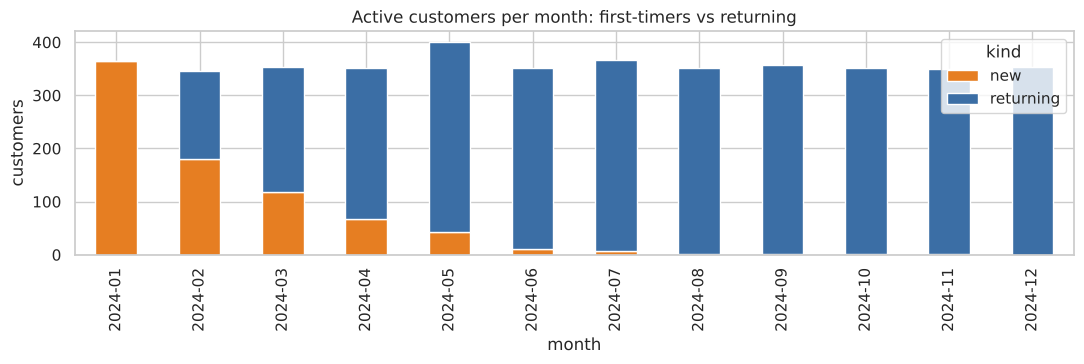

month,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12
kind,,,,,,,,,,,,
new,365,181,119,68,42,11,7,2,2,1,1,0
returning,0,164,234,284,359,341,359,349,355,351,348,354


In [10]:
first_month = done.groupby("customer_id")["transaction_timestamp"].min().dt.to_period("M")
activity = (done.assign(month=done["transaction_timestamp"].dt.to_period("M"))[["customer_id", "month"]]
                .drop_duplicates())
activity["cohort"] = activity["customer_id"].map(first_month)
q9 = (activity.assign(kind=np.where(activity["month"] == activity["cohort"], "new", "returning"))
              .pivot_table(index="month", columns="kind", values="customer_id", aggfunc="count", fill_value=0))
q9.index = q9.index.astype(str)

assert q9["new"].tolist() == sql("q9")["new_customers"].tolist()
print("[pandas and SQL agree]")

q9.plot.bar(stacked=True, figsize=(11, 3.8), color=["#e67e22", "#3b6ea5"])
plt.title("Active customers per month: first-timers vs returning")
plt.ylabel("customers")
plt.tight_layout()
plt.show()
q9.T

## Q10. How concentrated is value across counties?

12 of 20 counties carry 80% of value   [pandas and SQL agree]


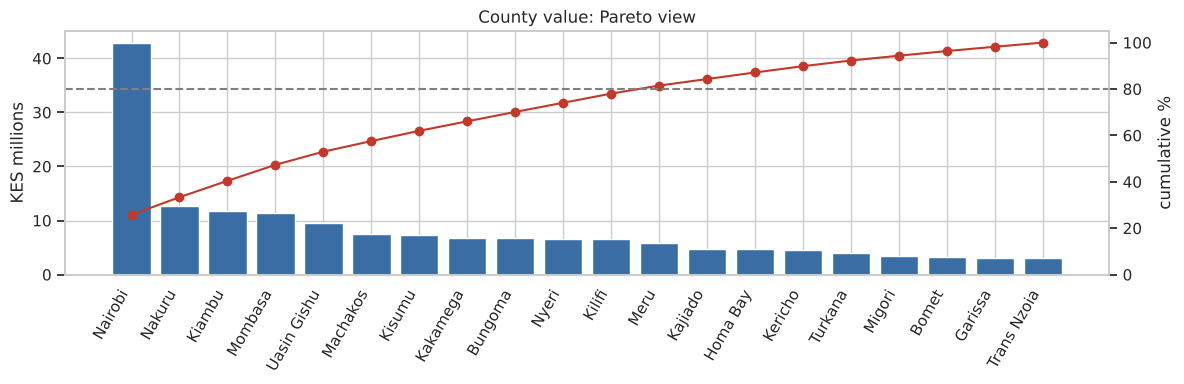

In [11]:
q10 = done.groupby("county")["amount_kes"].sum().sort_values(ascending=False).to_frame("value")
q10["cumulative_pct"] = (q10["value"].cumsum() / q10["value"].sum() * 100).round(2)
counties_for_80 = int((q10["cumulative_pct"] < 80).sum() + 1)

assert np.allclose(q10["cumulative_pct"].values, sql("q10")["cumulative_pct"].values, atol=0.01)
print(f"{counties_for_80} of {len(q10)} counties carry 80% of value   [pandas and SQL agree]")

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(q10.index, q10["value"] / 1e6, color="#3b6ea5")
ax.set_ylabel("KES millions")
ax2 = ax.twinx()
ax2.plot(q10.index, q10["cumulative_pct"], color="#c0392b", marker="o")
ax2.axhline(80, ls="--", color="grey")
ax2.set_ylabel("cumulative %")
ax2.set_ylim(0, 105)
ax2.grid(False)
ax.set_title("County value: Pareto view")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
plt.tight_layout()
plt.show()

## Business insights

- **Revenue is flat, not growing.** Monthly fee revenue stays between KES 31k and 37k all year. May was the best month (+11%), and June gave it all back (-15%). There's no seasonal trend to plan around.
- **The customer base stopped growing by mid-year.** 365 of the 800 customers joined in January, and new sign-ups fell to almost zero by July. From then on, activity is about 350 returning customers a month. **Acquisition, not retention, is the gap.**
- **Smaller channels are the least reliable.** T-Kash till payments fail or reverse 15% of the time and T-Kash Pay Bill 11%, against about 6% on M-Pesa. Those flows need reliability work before they get any promotion.
- **Mid-sized transactions pay the most in fees.** KES 1,001-5,000 transfers pay about 0.91% in fees, nearly 4x the 0.25% rate on transfers above KES 20,000. The structure favours large senders, which is where most of the value already sits.
- **Value is spread across counties, not concentrated.** It takes 12 of 20 counties to reach 80% of value, so there's no small set of counties to prioritise. A national approach fits better than a county-targeted one.
- **Champions are worth protecting.** The 121 Champion customers average KES 333k each, nearly 2x the "Others" group, and 130 high-value customers are already slipping into "At risk".